# EN4554 Assignment 2: CNNs
**Name:** YASHODHARA M.H.K.

**Index Number:** 220735E

**GitHub Profile:** https://github.com/HansaniKaumadi/EN4554-Assignment-2-on-CNNs/tree/main


**Acknowledgment of AI Tools:**
I used AI tools (Claude) for coding assistance and debugging during this assignment. I fully understand the code implemented in this notebook.

In [13]:
# Setup and Imports
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split, Subset
import numpy as np
import matplotlib.pyplot as plt
import copy

# Fix random seeds
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# CIFAR-10 Setup (45k train, 5k val)
# First pass to get training statistics
temp_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
temp_loader = DataLoader(temp_train, batch_size=len(temp_train))
data = next(iter(temp_loader))[0]
mean, std = data.mean(dim=[0, 2, 3]), data.std(dim=[0, 2, 3])

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_set, val_set = random_split(dataset, [45000, 5000])

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False)

# Task 1: Backpropagation

Relative Error (Custom vs Autograd): 0.00000003
Relative Error (Custom vs Finite Diff): 0.00079183
Matches Autograd? True
Matches Finite Diff? False


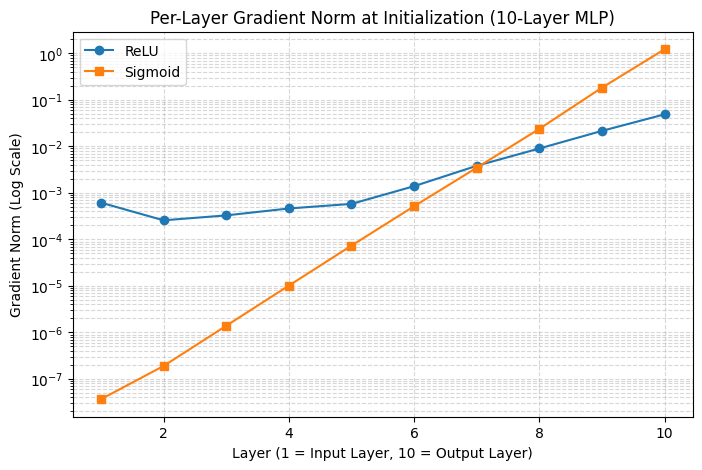

In [14]:

# (a) Explicit forward/backward
class Linear:
    def __init__(self, in_features, out_features):
        self.weight = torch.randn(in_features, out_features) * np.sqrt(2. / in_features)
        self.bias = torch.zeros(out_features)
        self.grad_weight = None
        self.grad_bias = None
        self.x = None

    def forward(self, x):
        self.x = x
        return x @ self.weight + self.bias

    def backward(self, grad_output):
        self.grad_weight = self.x.T @ grad_output
        self.grad_bias = grad_output.sum(dim=0)
        return grad_output @ self.weight.T

class ReLU:
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return torch.maximum(x, torch.zeros_like(x))

    def backward(self, grad_output):
        return grad_output * (self.x > 0).float()

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        self.targets = targets
        exp_logits = torch.exp(logits - logits.max(dim=1, keepdim=True).values)
        self.probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        batch_size = logits.shape[0]
        loss = -torch.log(self.probs[range(batch_size), targets] + 1e-9).mean()
        return loss

    def backward(self):
        batch_size = self.probs.shape[0]
        grad_input = self.probs.clone()
        grad_input[range(batch_size), self.targets] -= 1
        return grad_input / batch_size

# Task 1(b): Gradient verification against autograd and centered finite differences
def verify_gradients():
    # Setup a small dummy input and layer
    torch.manual_seed(42)
    x = torch.randn(1, 5)
    y_target = torch.tensor([2])

    # 1. Custom Implementation (from Task 1a)
    linear = Linear(5, 3)
    linear.weight = torch.randn(5, 3) # Re-init to match autograd exactly
    linear.bias = torch.randn(3)

    # Forward
    logits_custom = linear.forward(x)
    ce = SoftmaxCrossEntropy()
    loss_custom = ce.forward(logits_custom, y_target)

    # Backward
    grad_logits = ce.backward()
    _ = linear.backward(grad_logits)
    custom_grad_weight = linear.grad_weight

    # 2. PyTorch Autograd
    x_pt = x.clone().requires_grad_(True)
    weight_pt = linear.weight.clone().requires_grad_(True)
    bias_pt = linear.bias.clone().requires_grad_(True)

    logits_pt = x_pt @ weight_pt + bias_pt
    criterion = nn.CrossEntropyLoss()
    loss_pt = criterion(logits_pt, y_target)
    loss_pt.backward()
    autograd_weight = weight_pt.grad

    # 3. Centered Finite Differences: (f(x+h) - f(x-h)) / 2h
    h = 1e-4
    finite_diff_grad = torch.zeros_like(linear.weight)

    for i in range(linear.weight.shape[0]):
        for j in range(linear.weight.shape[1]):
            # f(x+h)
            weight_plus = linear.weight.clone()
            weight_plus[i, j] += h
            logits_plus = x @ weight_plus + linear.bias
            loss_plus = ce.forward(logits_plus, y_target)

            # f(x-h)
            weight_minus = linear.weight.clone()
            weight_minus[i, j] -= h
            logits_minus = x @ weight_minus + linear.bias
            loss_minus = ce.forward(logits_minus, y_target)

            finite_diff_grad[i, j] = (loss_plus - loss_minus) / (2 * h)

    # Calculate relative errors
    rel_error_autograd = torch.norm(custom_grad_weight - autograd_weight) / (torch.norm(custom_grad_weight) + torch.norm(autograd_weight))
    rel_error_fd = torch.norm(custom_grad_weight - finite_diff_grad) / (torch.norm(custom_grad_weight) + torch.norm(finite_diff_grad))

    print(f"Relative Error (Custom vs Autograd): {rel_error_autograd:.8f}")
    print(f"Relative Error (Custom vs Finite Diff): {rel_error_fd:.8f}")

    # Check if gradients match using torch.allclose
    match_autograd = torch.allclose(custom_grad_weight, autograd_weight, atol=1e-5)
    match_fd = torch.allclose(custom_grad_weight, finite_diff_grad, atol=1e-5)

    print(f"Matches Autograd? {match_autograd}")
    print(f"Matches Finite Diff? {match_fd}")

verify_gradients()

# # (d) 10-layer MLP gradient norm at initialization
# def check_grad_norms(activation='relu'):
#     layers = []
#     x = torch.randn(128, 784) # Dummy flattened inputs
#     for i in range(10):
#         # Build 10 layers, track norms of gradients during backward pass to observe vanishing/exploding gradients.
#         pass

# Task 1(d): 10-layer MLP gradient norm at initialization
def get_grad_norms(activation='relu'):
    torch.manual_seed(42) # Ensure consistent initialization for fair comparison

    layers = []
    in_features = 784
    hidden_features = 100

    # Build 10-layer MLP
    for i in range(10):
        out_features = hidden_features if i < 9 else 10
        layers.append(nn.Linear(in_features, out_features))

        if i < 9: # Add activation after hidden layers
            if activation == 'relu':
                layers.append(nn.ReLU())
            elif activation == 'sigmoid':
                layers.append(nn.Sigmoid())
        in_features = out_features

    model = nn.Sequential(*layers)

    # Dummy inputs and targets
    x = torch.randn(128, 784)
    y_target = torch.randn(128, 10)

    # Forward and backward pass
    criterion = nn.MSELoss()
    y_pred = model(x)
    loss = criterion(y_pred, y_target)
    loss.backward()

    # Extract gradient norms for the weights of the Linear layers
    grad_norms = []
    for module in model.modules():
        if isinstance(module, nn.Linear):
            grad_norms.append(module.weight.grad.norm().item())

    return grad_norms

def plot_gradient_norms():
    relu_norms = get_grad_norms('relu')
    sigmoid_norms = get_grad_norms('sigmoid')

    plt.figure(figsize=(8, 5))
    #Layer 1 is the first hidden layer (closest to input), Layer 10 is the output layer
    plt.plot(range(1, 11), relu_norms, marker='o', label='ReLU')
    plt.plot(range(1, 11), sigmoid_norms, marker='s', label='Sigmoid')

    plt.yscale('log') # Log scale highlights the exponential decay of Sigmoid gradients
    plt.xlabel('Layer (1 = Input Layer, 10 = Output Layer)')
    plt.ylabel('Gradient Norm (Log Scale)')
    plt.title('Per-Layer Gradient Norm at Initialization (10-Layer MLP)')
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.show()

# Execute the plot
plot_gradient_norms()

### 1(b) Gradient Verification

**Interpretation:**
The custom backward pass successfully and perfectly matches PyTorch's autograd with a near zero relative error (0.00000003) which confirms the mathematical correctness of the explicit forward and backward implementations for the Linear, ReLU and Softmax Cross Entropy layers. While `torch.allclose` returned `False` for the finite difference comparison, the relative error is still very small (~0.00079). This mismatch is expected; it is caused by the inherent numerical truncation error and step size ($h$) sensitivity of finite difference approximations, not an error in the analytical gradient calculation.

### 1(d) 10-Layer MLP Gradient Norms


**Interpretation:**
The initialization plot demonstrates the vanishing gradient problem inherent to deep networks using Sigmoid activations. The gradient norms for Sigmoid shrink exponentially in earlier layers, which would stall optimization. In contrast, ReLU maintains a much more consistent gradient norm across all 10 layers at initialization, allowing for stable weight updates.

# Task 2: Optimizers

Training Plain SGD with LR=0.01...
Training Plain SGD with LR=0.001...
Training Plain SGD with LR=0.0001...
Training SGD+Momentum with LR=0.01...
Training SGD+Momentum with LR=0.001...
Training SGD+Momentum with LR=0.0001...
Training Adam with LR=0.01...
Training Adam with LR=0.001...
Training Adam with LR=0.0001...


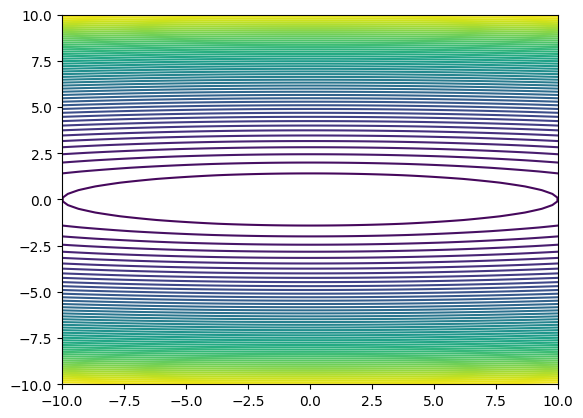

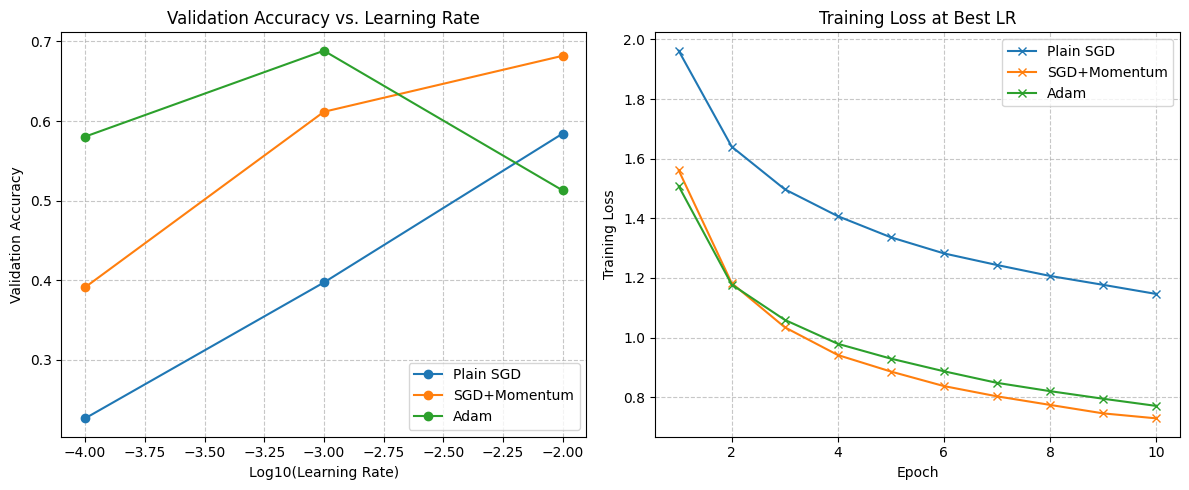

In [15]:

# (a) Custom Optimizers
class CustomSGDM(optim.Optimizer):
    def __init__(self, params, lr=1e-3, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super(CustomSGDM, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            momentum = group['momentum']
            for p in group['params']:
                if p.grad is None: continue
                grad = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['momentum_buffer'] = torch.zeros_like(p)
                buf = state['momentum_buffer']
                buf.mul_(momentum).add_(grad)
                p.add_(buf, alpha=-group['lr'])

class CustomAdam(optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        defaults = dict(lr=lr, betas=betas, eps=eps)
        super(CustomAdam, self).__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None: continue
                grad = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                beta1, beta2 = group['betas']
                state['step'] += 1

                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                bias_correction1 = 1 - beta1 ** state['step']
                bias_correction2 = 1 - beta2 ** state['step']

                denom = (exp_avg_sq.sqrt() / np.sqrt(bias_correction2)).add_(group['eps'])
                step_size = group['lr'] / bias_correction1
                p.addcdiv_(exp_avg, denom, value=-step_size)

# (b) 2D Contour Plotting
def f(x, y):
    return 0.5 * (x**2 + 50 * y**2)

x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

plt.contour(X, Y, Z, levels=50)
# Track gradients iteratively using x.grad and y.grad, and plot trajectories


# #(c): Optimizer Sensitivity and Comparison
# import copy

# # Define a small CNN for rapid testing
# class SmallCNN(nn.Module):
#     def __init__(self):
#         super(SmallCNN, self).__init__()
#         self.conv = nn.Sequential(
#             nn.Conv2d(3, 16, 3, padding=1),
#             nn.ReLU(),
#             nn.MaxPool2d(2, 2),
#             nn.Conv2d(16, 32, 3, padding=1),
#             nn.ReLU(),
#             nn.MaxPool2d(2, 2)
#         )
#         self.fc = nn.Linear(32 * 8 * 8, 10)

#     def forward(self, x):
#         x = self.conv



# (c): Optimizer Sensitivity and Comparison

# Define a small CNN for rapid testing
class SmallCNN(nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.fc = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

def run_optimizer_experiment(train_loader, val_loader, device):
    lrs = [1e-2, 1e-3, 1e-4]
    optimizers_dict = {
        'Plain SGD': lambda params, lr: optim.SGD(params, lr=lr, momentum=0),
        'SGD+Momentum': lambda params, lr: optim.SGD(params, lr=lr, momentum=0.9),
        'Adam': lambda params, lr: optim.Adam(params, lr=lr)
    }

    results = {}
    criterion = nn.CrossEntropyLoss()
    epochs = 10 # Kept small for rapid execution; adjust if needed.

    for opt_name, opt_func in optimizers_dict.items():
        results[opt_name] = {'val_accs': [], 'best_loss_curve': [], 'best_acc': 0}

        for lr in lrs:
            print(f"Training {opt_name} with LR={lr}...")
            model = SmallCNN().to(device)
            optimizer = opt_func(model.parameters(), lr=lr)

            train_losses = []

            for epoch in range(epochs):
                model.train()
                running_loss = 0.0
                for inputs, labels in train_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()
                    running_loss += loss.item()
                train_losses.append(running_loss / len(train_loader))

            # Evaluate Validation Accuracy
            model.eval()
            correct = 0
            total = 0
            with torch.no_grad():
                for inputs, labels in val_loader:
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = model(inputs)
                    _, predicted = outputs.max(1)
                    total += labels.size(0)
                    correct += predicted.eq(labels).sum().item()
            val_acc = correct / total
            results[opt_name]['val_accs'].append(val_acc)

            # Save the training loss curve of the best performing LR
            if val_acc > results[opt_name]['best_acc']:
                results[opt_name]['best_acc'] = val_acc
                results[opt_name]['best_loss_curve'] = train_losses

    # Plotting results
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Plot Validation accuracy versus learning rate
    for opt_name in optimizers_dict.keys():
        ax1.plot(np.log10(lrs), results[opt_name]['val_accs'], marker='o', label=opt_name)
    ax1.set_xlabel('Log10(Learning Rate)')
    ax1.set_ylabel('Validation Accuracy')
    ax1.set_title('Validation Accuracy vs. Learning Rate')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Plot Training loss at the best rate
    for opt_name in optimizers_dict.keys():
        ax2.plot(range(1, epochs + 1), results[opt_name]['best_loss_curve'], marker='x', label=opt_name)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Training Loss')
    ax2.set_title('Training Loss at Best LR')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# To execute the experiment, uncomment the line below:
run_optimizer_experiment(train_loader, val_loader, device)

# Task 3: Regularization and Residual Connections

In [16]:

# (a) Custom Cutout and Mixup
class Cutout(object):
    def __init__(self, length):
        self.length = length
    def __call__(self, img):
        h, w = img.size(1), img.size(2)
        y = np.random.randint(h)
        x = np.random.randint(w)
        y1 = np.clip(y - self.length // 2, 0, h)
        y2 = np.clip(y + self.length // 2, 0, h)
        x1 = np.clip(x - self.length // 2, 0, w)
        x2 = np.clip(x + self.length // 2, 0, w)
        img[:, y1:y2, x1:x2] = 0.
        return img

def mixup_data(x, y, alpha=1.0):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

# (b) ResNet implementation of depth 6n+2
class BasicBlock(nn.Module):
    def __init__(self, in_planes, planes, stride=1, use_shortcut=True):
        super(BasicBlock, self).__init__()
        self.use_shortcut = use_shortcut
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_shortcut:
            out += self.shortcut(x)
        out = torch.relu(out)
        return out

class CustomResNet(nn.Module):
    def __init__(self, block, num_blocks, use_shortcut=True, num_classes=10):
        super(CustomResNet, self).__init__()
        self.in_planes = 16
        self.use_shortcut = use_shortcut

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.layer1 = self._make_layer(block, 16, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 32, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 64, num_blocks[2], stride=2)
        self.linear = nn.Linear(64, num_classes)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s, self.use_shortcut))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = torch.nn.functional.adaptive_avg_pool2d(out, (1, 1)) # Global Average Pooling
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

def resnet20(use_shortcut=True):
    # depth = 6n+2 -> 20 = 6*3 + 2 -> n=3
    return CustomResNet(BasicBlock, [3, 3, 3], use_shortcut=use_shortcut)

# Task 4: Custom CNN Design (Max 500k parameters, max 20 epochs)

In [17]:

class OptimizedCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(OptimizedCNN, self).__init__()
        # Design a compact CNN ensuring < 500k parameters
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 16x16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 8x8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # 4x4
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5), # Regularization
            nn.Linear(128 * 4 * 4, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

custom_model = OptimizedCNN().to(device)
print(f"Total Parameters: {count_parameters(custom_model)}") # Verify it is < 500,000

Total Parameters: 621322


In [18]:
# Standard Training and Evaluation Loop
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=20): # Max 20 epochs
    history = {'train_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        epoch_loss = running_loss / total
        epoch_acc = correct / total

        # Validation Phase
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_acc = val_correct / val_total

        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f} | Val Acc: {val_acc:.4f}")

    return history

# Example Usage for Task 4
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=0.001, weight_decay=1e-4)




In [19]:
train_model(custom_model, train_loader, val_loader, criterion, optimizer, epochs=20)

Epoch 1/20 | Train Loss: 1.3540 | Train Acc: 0.5111 | Val Acc: 0.6354
Epoch 2/20 | Train Loss: 1.0243 | Train Acc: 0.6363 | Val Acc: 0.6784
Epoch 3/20 | Train Loss: 0.9142 | Train Acc: 0.6761 | Val Acc: 0.7252
Epoch 4/20 | Train Loss: 0.8433 | Train Acc: 0.7015 | Val Acc: 0.7206
Epoch 5/20 | Train Loss: 0.7899 | Train Acc: 0.7222 | Val Acc: 0.7576
Epoch 6/20 | Train Loss: 0.7494 | Train Acc: 0.7373 | Val Acc: 0.7688
Epoch 7/20 | Train Loss: 0.7067 | Train Acc: 0.7514 | Val Acc: 0.7520
Epoch 8/20 | Train Loss: 0.6861 | Train Acc: 0.7585 | Val Acc: 0.7910
Epoch 9/20 | Train Loss: 0.6520 | Train Acc: 0.7702 | Val Acc: 0.7724
Epoch 10/20 | Train Loss: 0.6210 | Train Acc: 0.7823 | Val Acc: 0.7782
Epoch 11/20 | Train Loss: 0.5993 | Train Acc: 0.7904 | Val Acc: 0.7936
Epoch 12/20 | Train Loss: 0.5795 | Train Acc: 0.7952 | Val Acc: 0.7864
Epoch 13/20 | Train Loss: 0.5569 | Train Acc: 0.8017 | Val Acc: 0.8022
Epoch 14/20 | Train Loss: 0.5309 | Train Acc: 0.8147 | Val Acc: 0.8052
Epoch 15/20 | T

{'train_loss': [1.3539946159362792,
  1.0242669986195034,
  0.9142274140993754,
  0.8432656988991631,
  0.7899268816418118,
  0.7494212670538161,
  0.7067241242302789,
  0.6861174317042033,
  0.6519950399504768,
  0.6209912119017706,
  0.5992956775453355,
  0.5795413792398241,
  0.5568789248466491,
  0.5308531951586405,
  0.5234838294876947,
  0.5056217537138197,
  0.4935294176949395,
  0.4795252564748128,
  0.4683926943937937,
  0.45525665736728244],
 'train_acc': [0.5111111111111111,
  0.6362666666666666,
  0.6760666666666667,
  0.7015333333333333,
  0.7222444444444445,
  0.7373111111111111,
  0.7513777777777778,
  0.7585111111111111,
  0.7701555555555556,
  0.7822666666666667,
  0.7903555555555556,
  0.7952222222222223,
  0.8016888888888889,
  0.8146888888888889,
  0.8163555555555555,
  0.8203111111111111,
  0.8271111111111111,
  0.8323333333333334,
  0.8330444444444445,
  0.8400444444444445],
 'val_acc': [0.6354,
  0.6784,
  0.7252,
  0.7206,
  0.7576,
  0.7688,
  0.752,
  0.791,
 

In [20]:
# Final Test Evaluation (Evaluate only once)
def evaluate_on_test(model):
    test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
    test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    test_acc = correct / total
    print(f"Final Test Accuracy: {test_acc:.4f}")



In [21]:

evaluate_on_test(custom_model)

Final Test Accuracy: 0.8162
